# Project Task — Linear Regression & Random Forest (hourly, leave-one-year-out CV)

> **Update (hourly + year CV).** Previously this notebook trained on **daily** features with a
> single chronological train/val/test split. It now trains on the **hourly** feature table from
> the rebuilt preprocessing notebook, and evaluates with **leave-one-year-out (LOYO) cross-validation**
> across the 8 study years (2013–2020): each year is held out as the test fold exactly once while the
> model trains on the other 7, so we can report *which warm-season year each model performs best on*
> instead of relying on one arbitrary held-out slice.


### Step 1 — Setup

In [1]:
import os, sys
from pathlib import Path

def detect_platform() -> str:
    if 'google.colab' in sys.modules or 'COLAB_GPU' in os.environ:
        return 'colab'
    if os.environ.get('KAGGLE_KERNEL_RUN_TYPE'):
        return 'kaggle'
    return 'local'

PLATFORM = detect_platform()
if PLATFORM == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/ITEC 4000')
    print('Colab: cwd set to', os.getcwd())
else:
    print('Platform:', PLATFORM)


Platform: local


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer

SEED = 42
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / 'README.md').exists() and (candidate / 'data').is_dir():
        PROJECT_ROOT = candidate
        break
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from hydro_course.paths import OUTPUTS_DIR, ensure_module_dirs
from hydro_course.metrics import hydrology_metrics, regression_metrics

paths = ensure_module_dirs('module_04')
M3_FEATURES = OUTPUTS_DIR / 'module_03' / 'hy024_clean_features.csv'
print('M3 features exist:', M3_FEATURES.exists())


M3 features exist: True


### Step 2 — Load hourly features

In [3]:
df = pd.read_csv(M3_FEATURES, index_col=0, parse_dates=True)
assert df.index.month.isin([4, 5, 6, 7, 8, 9, 10, 11]).all(), 'Warm season only (April-Nov)'

TARGET = 'q'
STUDY_YEARS = sorted(df['year'].unique().tolist())
FEATURE_COLS = [c for c in df.columns if c not in (TARGET, 'year')]
print('Rows:', len(df), '| Features:', len(FEATURE_COLS), '| Study years:', STUDY_YEARS)
print('Rows per year:\n', df.groupby('year').size())


Rows: 43967 | Features: 18 | Study years: [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]
Rows per year:
 year
2013    5496
2014    5496
2015    5496
2016    5495
2017    5496
2018    5496
2019    5496
2020    5496
dtype: int64


### Step 3 — Per-warm-season-year normalization stats (Meeting 1 rule)

Each year's feature columns are standardized using **that year's own full-season** mean/std
(not train-only statistics). This is a deliberate course convention, not an oversight — it treats
every warm season as a self-contained regime. It does mean a held-out test year is scaled using
information from its own season (documented as a known, bounded form of leakage in
`outputs/project/task1_study_design.json`); a train-only-scaling sensitivity check is worth
reporting alongside this in the final write-up, but is out of scope for this notebook.


In [4]:
year_stats = {}
for y in STUDY_YEARS:
    m = df['year'] == y
    year_stats[y] = {
        'mean': df.loc[m, FEATURE_COLS].mean(),
        'std':  df.loc[m, FEATURE_COLS].std().replace(0, 1.0),
    }

def scale_per_year(sub_df: pd.DataFrame) -> np.ndarray:
    out = sub_df[FEATURE_COLS].copy()
    for y, s in year_stats.items():
        m = sub_df['year'] == y
        if m.any():
            out.loc[m] = (out.loc[m] - s['mean']) / s['std']
    return out.values


### Step 4 — Leave-one-year-out cross-validation

For each of the 8 study years, that year is the **held-out test fold**; the model trains on the
pooled other 7 years. We also score two baselines on every fold for context:
- **Persistence** — `q_lag1` (last hour's value)
- **24h moving average** — `q_roll24_mean` (trailing past-day mean; the hourly analogue of the
  old 7-day benchmark)

Feature imputation (mean fill for any stray NaN) is fit **on the training fold only** and applied
to both train and test, so no test-fold information leaks into the imputer.


In [5]:
RF_PARAMS = dict(n_estimators=200, max_depth=12, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
print('RF hyperparameters:', RF_PARAMS)

fold_rows = []
fold_predictions = {}  # year -> dict of arrays, for plotting later

for held_out in STUDY_YEARS:
    train_df = df[df['year'] != held_out].copy()
    test_df  = df[df['year'] == held_out].copy()

    imputer = SimpleImputer(strategy='mean').fit(train_df[FEATURE_COLS])
    train_df[FEATURE_COLS] = imputer.transform(train_df[FEATURE_COLS])
    test_df[FEATURE_COLS]  = imputer.transform(test_df[FEATURE_COLS])

    X_train_s, y_train = scale_per_year(train_df), train_df[TARGET].values
    X_test_s,  y_test  = scale_per_year(test_df),  test_df[TARGET].values
    X_train, X_test    = train_df[FEATURE_COLS].values, test_df[FEATURE_COLS].values

    lin = LinearRegression().fit(X_train_s, y_train)
    rf  = RandomForestRegressor(**RF_PARAMS).fit(X_train, y_train)

    y_persist = test_df['q_lag1'].values
    y_ma24    = test_df['q_roll24_mean'].values
    y_lin     = lin.predict(X_test_s)
    y_rf      = rf.predict(X_test)

    for model_name, y_pred in [('Persistence (lag-1)', y_persist),
                               ('24h moving average', y_ma24),
                               ('Linear Regression',   y_lin),
                               ('Random Forest',       y_rf)]:
        fold_rows.append({'held_out_year': held_out, 'model': model_name,
                           'n_test': len(y_test), **hydrology_metrics(y_test, y_pred)})

    fold_predictions[held_out] = {'dates': test_df.index, 'y_test': y_test,
                                   'y_persist': y_persist, 'y_ma24': y_ma24,
                                   'y_lin': y_lin, 'y_rf': y_rf,
                                   'lin_model': lin, 'rf_model': rf}
    print(f'Fold held_out={held_out}: train n={len(train_df):,}  test n={len(test_df):,}  done')

cv_results = pd.DataFrame(fold_rows)
print(cv_results.round(4).to_string(index=False))


RF hyperparameters: {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 3, 'random_state': 42, 'n_jobs': -1}


Fold held_out=2013: train n=38,471  test n=5,496  done


Fold held_out=2014: train n=38,471  test n=5,496  done


Fold held_out=2015: train n=38,471  test n=5,496  done


Fold held_out=2016: train n=38,472  test n=5,495  done


Fold held_out=2017: train n=38,471  test n=5,496  done


Fold held_out=2018: train n=38,471  test n=5,496  done


Fold held_out=2019: train n=38,471  test n=5,496  done


Fold held_out=2020: train n=38,471  test n=5,496  done
 held_out_year               model  n_test   RMAE     MAPE     NSE     KGE
          2013 Persistence (lag-1)    5496 0.1434   5.9536  0.9497  0.9748
          2013  24h moving average    5496 0.6386  41.5345  0.4080  0.6204
          2013   Linear Regression    5496 0.4293  45.9372  0.6809  0.3571
          2013       Random Forest    5496 0.1869  10.6791  0.8173  0.6676
          2014 Persistence (lag-1)    5496 0.1876   6.6413  0.8552  0.9276
          2014  24h moving average    5496 0.6789  48.9896  0.1876  0.3866
          2014   Linear Regression    5496 0.2730  76.2490  0.9027  0.8508
          2014       Random Forest    5496 0.1438  10.1403  0.9004  0.9364
          2015 Persistence (lag-1)    5496 0.1255   4.6467  0.9287  0.9643
          2015  24h moving average    5496 0.5528  33.4568  0.4028  0.5985
          2015   Linear Regression    5496 0.2357  29.0029  0.9188  0.8383
          2015       Random Forest    5496 0.

### Step 5 — Best-performing held-out year per model

In [6]:
summary_rows = []
for model_name, g in cv_results.groupby('model'):
    best = g.loc[g['NSE'].idxmax()]
    summary_rows.append({
        'model': model_name,
        'best_year': int(best['held_out_year']),
        'best_year_NSE': best['NSE'], 'best_year_KGE': best['KGE'],
        'best_year_RMAE': best['RMAE'], 'best_year_MAPE': best['MAPE'],
        'cv_mean_NSE': g['NSE'].mean(), 'cv_std_NSE': g['NSE'].std(),
        'cv_mean_KGE': g['KGE'].mean(), 'cv_std_KGE': g['KGE'].std(),
    })
best_year_summary = pd.DataFrame(summary_rows).sort_values('cv_mean_NSE', ascending=False)
print(best_year_summary.round(4).to_string(index=False))
print()
for _, r in best_year_summary.iterrows():
    print(f"{r['model']:>22}: best on held-out {int(r['best_year'])} "
          f"(NSE={r['best_year_NSE']:.3f}, KGE={r['best_year_KGE']:.3f}); "
          f"CV mean NSE={r['cv_mean_NSE']:.3f} +/- {r['cv_std_NSE']:.3f}")


              model  best_year  best_year_NSE  best_year_KGE  best_year_RMAE  best_year_MAPE  cv_mean_NSE  cv_std_NSE  cv_mean_KGE  cv_std_KGE
      Random Forest       2017         0.9568         0.9236          0.1060          5.6987       0.9026      0.0467       0.9077      0.0991
Persistence (lag-1)       2017         0.9569         0.9785          0.1092          5.0875       0.8892      0.0510       0.9446      0.0255
  Linear Regression       2017         0.9535         0.8527          0.1509         13.8604       0.6232      0.6449       0.5423      0.5219
 24h moving average       2017         0.5546         0.7208          0.5013         32.1587       0.3365      0.1479       0.5247      0.1449

         Random Forest: best on held-out 2017 (NSE=0.957, KGE=0.924); CV mean NSE=0.903 +/- 0.047
   Persistence (lag-1): best on held-out 2017 (NSE=0.957, KGE=0.978); CV mean NSE=0.889 +/- 0.051
     Linear Regression: best on held-out 2017 (NSE=0.953, KGE=0.853); CV mean NSE=0.623 

### Step 6 — Visualise CV performance across held-out years

NSE per held-out year, one line per model — shows both which year each model likes best and how
much performance varies year to year (a single best year can be optimistic; the spread matters too).


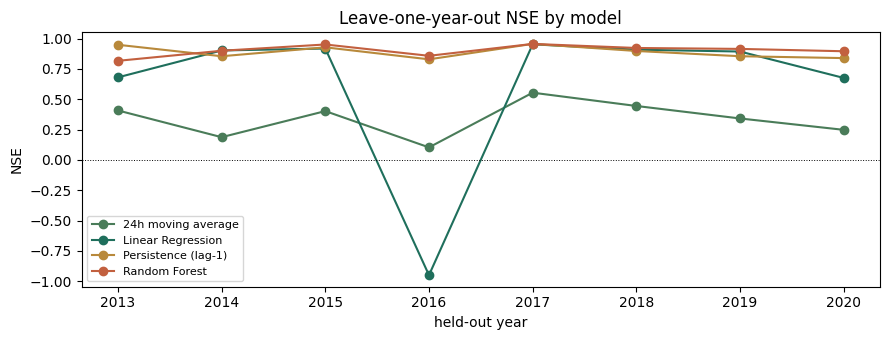

Saved -> /private/tmp/exec_root/figures/module_04/m4_cv_nse_by_year.png


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
colors = {'Persistence (lag-1)': '#b8893b', '24h moving average': '#4a7c59',
          'Linear Regression': '#1f6f5c', 'Random Forest': '#c2603f'}
for model_name, g in cv_results.groupby('model'):
    g = g.sort_values('held_out_year')
    ax.plot(g['held_out_year'], g['NSE'], marker='o', color=colors.get(model_name), label=model_name)
ax.axhline(0, color='black', lw=0.7, ls=':')
ax.set_xlabel('held-out year'); ax.set_ylabel('NSE')
ax.set_title('Leave-one-year-out NSE by model')
ax.legend(fontsize=8)
fig.tight_layout()
fig_path = paths['figures'] / 'm4_cv_nse_by_year.png'
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print('Saved ->', fig_path)


### Step 7 — Forecast hydrograph for each model's best held-out year

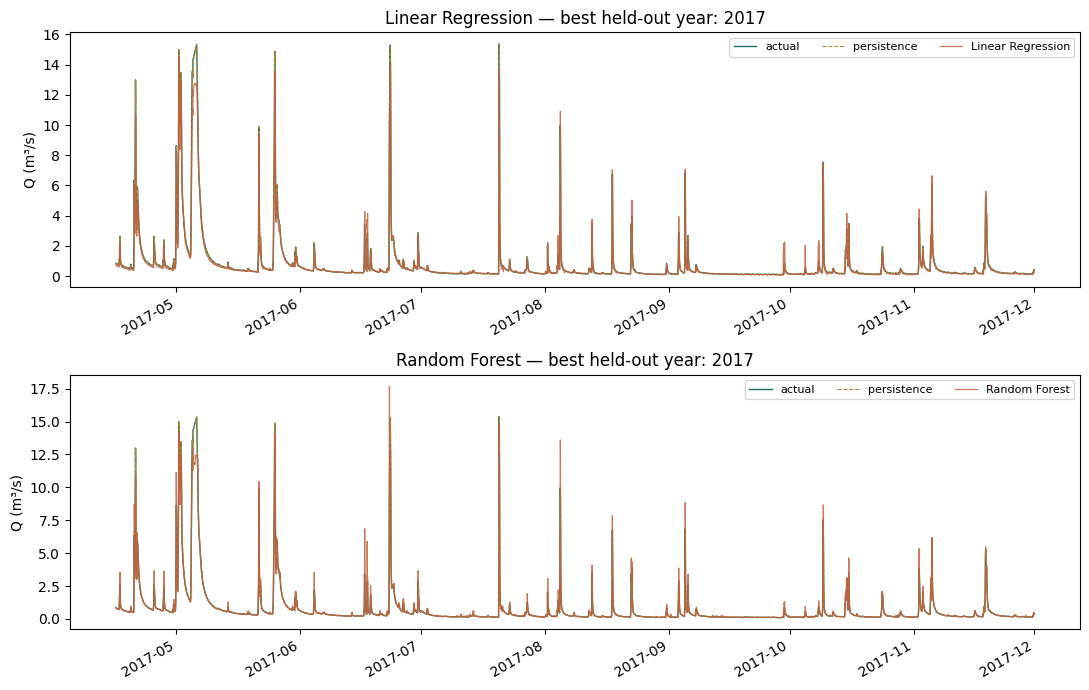

Saved -> /private/tmp/exec_root/figures/module_04/m4_forecast_best_years.png


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, model_name, pred_key in zip(axes, ['Linear Regression', 'Random Forest'], ['y_lin', 'y_rf']):
    best_year = int(best_year_summary.set_index('model').loc[model_name, 'best_year'])
    fp = fold_predictions[best_year]
    ax.plot(fp['dates'], fp['y_test'], color='#1f6f5c', lw=1.0, label='actual')
    ax.plot(fp['dates'], fp['y_persist'], color='#b8893b', lw=0.8, ls='--', label='persistence')
    ax.plot(fp['dates'], fp[pred_key], color='#c2603f', lw=0.9, alpha=0.85, label=model_name)
    ax.set_ylabel('Q (m\u00b3/s)')
    ax.set_title(f'{model_name} \u2014 best held-out year: {best_year}')
    ax.legend(loc='upper right', ncol=3, fontsize=8)
    # Each subplot has its own (potentially different) year on the x-axis, so date labels are
    # rotated per-axis here instead of via fig.autofmt_xdate() — that call only labels the
    # bottom-most subplot and silently blanks out the date ticks on the ones above it.
    for label in ax.get_xticklabels():
        label.set_rotation(30); label.set_ha('right')
fig.tight_layout()
fig_path = paths['figures'] / 'm4_forecast_best_years.png'
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print('Saved ->', fig_path)


### Step 8 — Final models (trained on all 8 years) + save

The CV loop above exists to *evaluate* generalization and find each model's best year. For a
model to actually use going forward, we refit on **all available years** pooled (still per-year
scaled) — this is the model that gets saved.


In [9]:
imputer_full = SimpleImputer(strategy='mean').fit(df[FEATURE_COLS])
df_imp = df.copy()
df_imp[FEATURE_COLS] = imputer_full.transform(df[FEATURE_COLS])

X_all_s, y_all = scale_per_year(df_imp), df_imp[TARGET].values
X_all = df_imp[FEATURE_COLS].values

lin_final = LinearRegression().fit(X_all_s, y_all)
rf_final  = RandomForestRegressor(**RF_PARAMS).fit(X_all, y_all)

joblib.dump({'model': lin_final, 'year_stats': year_stats, 'features': FEATURE_COLS, 'imputer': imputer_full},
            paths['models'] / 'm4_linear_regression.joblib')
joblib.dump({'model': rf_final, 'features': FEATURE_COLS, 'imputer': imputer_full},
            paths['models'] / 'm4_random_forest.joblib')

metrics_path = paths['outputs'] / 'm4_cv_results_by_year.csv'
cv_results.to_csv(metrics_path, index=False)
summary_path = paths['outputs'] / 'm4_best_year_summary.csv'
best_year_summary.to_csv(summary_path, index=False)

record = {
    'module': 'module_04',
    'source_features': str(M3_FEATURES),
    'target': TARGET,
    'feature_columns': FEATURE_COLS,
    'aggregation': 'hourly (previously daily)',
    'cv_scheme': 'leave-one-year-out across 8 study years (2013-2020)',
    'rf_hyperparameters': RF_PARAMS,
    'linear_regression_scaling': 'per-warm-season-year, fit on FULL-season statistics (Meeting 1 rule)',
    'best_year_by_model': best_year_summary.set_index('model')['best_year'].to_dict(),
    'cv_mean_nse_by_model': best_year_summary.set_index('model')['cv_mean_NSE'].to_dict(),
}
record_path = paths['outputs'] / 'm4_design_record.json'
record_path.write_text(json.dumps(record, indent=2, default=str))
print('Saved models  ->', paths['models'])
print('Saved CV table->', metrics_path)
print('Saved summary ->', summary_path)
print('Saved record  ->', record_path)


Saved models  -> /private/tmp/exec_root/models/module_04
Saved CV table-> /private/tmp/exec_root/outputs/module_04/m4_cv_results_by_year.csv
Saved summary -> /private/tmp/exec_root/outputs/module_04/m4_best_year_summary.csv
Saved record  -> /private/tmp/exec_root/outputs/module_04/m4_design_record.json
